In [1]:
import pandas as pd
import numpy as np

hurricanes = pd.read_csv("../../data/disaster_data/us_landfall_hurricanes_hurdat.csv")

# Convert dates
date_cols = [
    "start_date",
    "end_date",
    "first_us_landfall_date",
    "landfall_time"
]

for col in date_cols:
    hurricanes[col] = pd.to_datetime(
        hurricanes[col],
        errors="coerce"
    )

# Convert category strings to integers
hurricanes["peak_category_num"] = (
    hurricanes["peak_category"]
    .str.extract(r"(\d+)")[0]
    .astype(int)
)

hurricanes["landfall_category_num"] = (
    hurricanes["landfall_category"]
    .str.extract(r"(\d+)")[0]
    .astype(int)
)

# Use date associated with landfall measurements
hurricanes["event_date"] = (
    hurricanes["landfall_time"].dt.normalize()
)

print("Number of hurricanes:", len(hurricanes))

display(
    hurricanes[
        [
            "hurricane_name",
            "peak_category_num",
            "landfall_category_num",
            "event_date"
        ]
    ].head()
)

Number of hurricanes: 46


,hurricane_name,peak_category_num,landfall_category_num,event_date
0,Lili (2002),4,1,2002-10-03
1,Claudette (2003),1,1,2003-07-15
2,Isabel (2003),5,2,2003-09-18
3,Charley (2004),4,4,2004-08-13
4,Gaston (2004),1,1,2004-08-29


In [3]:
# 1. Peak hurricane intensity
hurricanes["cat3_plus"] = (
    hurricanes["peak_category_num"] >= 3
)

# 2. Intensity at landfall
hurricanes["landfall_cat3_plus"] = (
    hurricanes["landfall_category_num"] >= 3
)

# 3. Approximate Gulf Coast landfall
hurricanes["gulf_landfall"] = (
    hurricanes["landfall_lon"].between(-98, -81)
    & hurricanes["landfall_lat"].between(24, 31)
)

# 4. Peak hurricane season
hurricanes["peak_season"] = (
    hurricanes["event_date"].dt.month.isin([8, 9])
)

# 5. Days from formation to recorded landfall
hurricanes["days_to_landfall"] = (
    hurricanes["event_date"] - hurricanes["start_date"]
).dt.days

median_days = hurricanes["days_to_landfall"].median()

hurricanes["short_time_to_landfall"] = (
    hurricanes["days_to_landfall"] < median_days
)

# 6. Low atmospheric pressure at landfall
median_pressure = (
    hurricanes["landfall_pressure_mb"].median()
)

hurricanes["low_pressure"] = (
    hurricanes["landfall_pressure_mb"] < median_pressure
)

# 7. Multiple US landfalls
hurricanes["multiple_landfalls"] = (
    hurricanes["us_landfall_count"] > 1
)

In [4]:
storm_features = [
    "cat3_plus",
    "landfall_cat3_plus",
    "gulf_landfall",
    "peak_season",
    "short_time_to_landfall",
    "low_pressure",
    "multiple_landfalls"
]

feature_summary = pd.DataFrame({
    "Count": hurricanes[storm_features].sum(),
    "Percentage": (
        hurricanes[storm_features].mean() * 100
    ).round(1)
})

display(feature_summary)

,Count,Percentage
cat3_plus,29,63.0
landfall_cat3_plus,17,37.0
gulf_landfall,34,73.9
peak_season,28,60.9
short_time_to_landfall,20,43.5
low_pressure,23,50.0
multiple_landfalls,17,37.0


In [5]:
storm_transactions = hurricanes[
    ["storm_id", "hurricane_name", "event_date"]
    + storm_features
].copy()

display(storm_transactions.head())

,storm_id,hurricane_name,event_date,cat3_plus,landfall_cat3_plus,gulf_landfall,peak_season,short_time_to_landfall,low_pressure,multiple_landfalls
0,2002265N10315,Lili (2002),2002-10-03,True,False,True,False,False,False,False
1,2003188N11307,Claudette (2003),2003-07-15,False,False,True,False,False,False,False
2,2003249N14329,Isabel (2003),2003-09-18,True,False,False,True,False,True,False
3,2004223N11301,Charley (2004),2004-08-13,True,True,True,True,True,True,True
4,2004241N32282,Gaston (2004),2004-08-29,False,False,False,True,True,False,False


In [8]:

import pandas as pd
import numpy as np

market = pd.read_csv("../../data/stock_data/market_raw.csv")

market["Date"] = pd.to_datetime(market["Date"])

market = (
    market.sort_values("Date")
    .drop_duplicates(subset="Date")
    .reset_index(drop=True)
)

sectors = {
    "SPY": "market",
    "XLE": "energy",
    "XLF": "financials",
    "XLI": "industrials",
    "XLU": "utilities"
}

close_cols = [
    f"{ticker}_Close"
    for ticker in sectors
]

# Ensure numeric closing prices
for col in close_cols + ["^VIX_Close"]:
    market[col] = pd.to_numeric(
        market[col],
        errors="coerce"
    )

# SPY return over the previous 5 trading sessions
market["SPY_prior_5d"] = (
    market["SPY_Close"].pct_change(
        periods=5,
        fill_method=None
    ) * 100
)

display(market.head())

,Date,SPY_Open,SPY_High,SPY_Low,SPY_Close,SPY_Volume,XLE_Open,XLE_High,XLE_Low,XLE_Close,...,XLU_High,XLU_Low,XLU_Close,XLU_Volume,^VIX_Open,^VIX_High,^VIX_Low,^VIX_Close,^VIX_Volume,SPY_prior_5d
0,1999-11-24,87.979566,89.034384,87.510759,88.741379,4459700,6.767114,6.860133,6.751611,6.860133,...,5.691201,5.660220,5.669514,37600,20.700001,20.850000,20.100000,20.26,0,NaN
1,1999-11-26,89.053889,89.307827,88.292077,88.409279,1693900,6.805866,6.836873,6.759357,6.759357,...,5.762463,5.700501,5.734580,5000,20.350000,23.469999,20.219999,22.33,0,NaN
2,1999-11-29,88.057704,88.712081,87.784233,88.096771,7348600,6.724479,6.728355,6.685722,6.705100,...,5.688103,5.650926,5.669514,52200,24.270000,24.290001,23.110001,23.57,0,NaN
3,1999-11-30,87.979567,88.956249,86.885682,87.061485,7682000,6.701223,6.759359,6.677968,6.693471,...,5.812031,5.712892,5.740776,41400,23.809999,24.209999,22.860001,24.18,0,NaN
4,1999-12-01,87.081001,87.823280,86.885665,87.764679,6980200,6.681842,6.825246,6.681842,6.825246,...,5.784147,5.731479,5.768656,9600,23.410000,23.410000,22.230000,22.23,0,NaN


In [9]:
hurricanes = hurricanes.copy()

# Use the recorded landfall timestamp
hurricanes["event_date"] = pd.to_datetime(
    hurricanes["landfall_time"]
).dt.normalize()

market_dates = market["Date"].to_numpy(
    dtype="datetime64[ns]"
)

event_dates = hurricanes["event_date"].to_numpy(
    dtype="datetime64[ns]"
)

# Find first trading session on or after landfall
positions = np.searchsorted(
    market_dates,
    event_dates,
    side="left"
)

# Exclude events outside market coverage
valid = (
    hurricanes["event_date"].notna().to_numpy()
    & (positions < len(market))
)

hurricanes = hurricanes.loc[valid].copy()
hurricanes["market_idx"] = positions[valid]

hurricanes["event_trading_date"] = (
    market.iloc[hurricanes["market_idx"]]["Date"].to_numpy()
)

display(
    hurricanes[
        [
            "hurricane_name",
            "event_date",
            "event_trading_date"
        ]
    ]
)

,hurricane_name,event_date,event_trading_date
0,Lili (2002),2002-10-03,2002-10-03
1,Claudette (2003),2003-07-15,2003-07-15
2,Isabel (2003),2003-09-18,2003-09-18
3,Charley (2004),2004-08-13,2004-08-13
4,Gaston (2004),2004-08-29,2004-08-30
5,Frances (2004),2004-09-05,2004-09-07
6,Ivan (2004),2004-09-16,2004-09-16
7,Jeanne (2004),2004-09-26,2004-09-27
8,Cindy (2005),2005-07-06,2005-07-06
9,Dennis (2005),2005-07-10,2005-07-11


In [10]:
# Find the previous trading session
hurricanes["prior_market_idx"] = (
    np.searchsorted(
        market_dates,
        hurricanes["event_date"].to_numpy(
            dtype="datetime64[ns]"
        ),
        side="left"
    ) - 1
)

# Require enough historical sessions
hurricanes = hurricanes[
    hurricanes["prior_market_idx"] >= 5
].copy()

prior_idx = hurricanes["prior_market_idx"].to_numpy()

hurricanes["vix_prior"] = (
    market.iloc[prior_idx]["^VIX_Close"].to_numpy()
)

hurricanes["spy_prior_5d_return"] = (
    market.iloc[prior_idx]["SPY_prior_5d"].to_numpy()
)

# Median across hurricanes, not across all market dates
median_vix = hurricanes["vix_prior"].median()

hurricanes["high_vix"] = (
    hurricanes["vix_prior"] > median_vix
)

hurricanes["market_down_prior"] = (
    hurricanes["spy_prior_5d_return"] < 0
)

display(
    hurricanes[
        [
            "hurricane_name",
            "vix_prior",
            "spy_prior_5d_return",
            "high_vix",
            "market_down_prior"
        ]
    ].head()
)

,hurricane_name,vix_prior,spy_prior_5d_return,high_vix,market_down_prior
0,Lili (2002),36.830002,-1.422683,True,True
1,Claudette (2003),19.590000,0.029800,True,False
2,Isabel (2003),18.150000,1.392670,True,False
3,Charley (2004),19.080000,-1.309975,True,True
4,Gaston (2004),14.710000,0.877963,False,False


In [11]:
def calculate_sector_returns(hurricanes, market, days):

    results = []

    for _, storm in hurricanes.iterrows():

        start_idx = int(storm["market_idx"])
        end_idx = start_idx + days

        # Skip storms without a full return window
        if end_idx >= len(market):
            continue

        start = market.iloc[start_idx]
        end = market.iloc[end_idx]

        row = {
            "storm_id": storm["storm_id"],
            "hurricane_name": storm["hurricane_name"],
            "window": f"0_to_{days}"
        }

        for ticker, sector in sectors.items():

            start_price = start[f"{ticker}_Close"]
            end_price = end[f"{ticker}_Close"]

            if (
                pd.isna(start_price)
                or pd.isna(end_price)
                or start_price <= 0
            ):
                row[sector] = np.nan
            else:
                row[sector] = (
                    (end_price / start_price) - 1
                ) * 100

        results.append(row)

    return pd.DataFrame(results)

In [12]:
returns_5 = calculate_sector_returns(
    hurricanes, market, 5
)

returns_14 = calculate_sector_returns(
    hurricanes, market, 14
)

display(returns_5.head())
display(returns_14.head())

,storm_id,hurricane_name,window,market,energy,financials,industrials,utilities
0,2002265N10315,Lili (2002),0_to_5,-2.041045,-3.681537,-1.409805,-4.561691,-11.147490
1,2003188N11307,Claudette (2003),0_to_5,-1.333218,1.158771,-1.157902,1.651037,-0.142841
2,2003249N14329,Isabel (2003),0_to_5,-3.762017,0.503563,-3.088185,-4.011758,-0.944051
3,2004223N11301,Charley (2004),0_to_5,3.069290,0.931562,3.962256,3.178845,0.980755
4,2004241N32282,Gaston (2004),0_to_5,2.108025,4.358934,2.436544,2.342349,1.930795


,storm_id,hurricane_name,window,market,energy,financials,industrials,utilities
0,2002265N10315,Lili (2002),0_to_14,9.585728,3.359443,14.048393,7.329634,-4.972629
1,2003188N11307,Claudette (2003),0_to_14,-1.989818,-1.716740,-2.933298,2.632724,-2.142861
2,2003249N14329,Isabel (2003),0_to_14,-0.191965,3.208622,1.062465,-1.563059,1.358555
3,2004223N11301,Charley (2004),0_to_14,5.028425,5.268224,5.743370,5.721770,3.187583
4,2004241N32282,Gaston (2004),0_to_14,2.178786,8.384665,1.241718,2.845249,1.687424


In [13]:
def create_outcomes(returns_df):

    outcome_df = returns_df[
        ["storm_id"]
    ].copy()

    for sector in sectors.values():

        outcome_df[f"{sector}_up"] = (
            returns_df[sector] > 0
        )

        outcome_df[f"{sector}_down"] = (
            returns_df[sector] < 0
        )

    return outcome_df

In [14]:
outcomes_5 = create_outcomes(returns_5)
outcomes_14 = create_outcomes(returns_14)

In [15]:
storm_features = [
    "cat3_plus",
    "landfall_cat3_plus",
    "gulf_landfall",
    "peak_season",
    "short_time_to_landfall",
    "low_pressure",
    "multiple_landfalls",
    "high_vix",
    "market_down_prior"
]

def build_transactions(hurricanes, returns_df):

    # Require complete returns for all sectors
    valid_returns = returns_df.dropna(
        subset=list(sectors.values())
    ).copy()

    outcomes = create_outcomes(valid_returns)

    transactions = hurricanes[
        ["storm_id"] + storm_features
    ].merge(
        outcomes,
        on="storm_id",
        how="inner",
        validate="one_to_one"
    )

    transactions = transactions.set_index("storm_id")

    return transactions.astype(bool)

In [16]:
transactions_5 = build_transactions(
    hurricanes, returns_5
)

transactions_14 = build_transactions(
    hurricanes, returns_14
)

print("5-day storms:", len(transactions_5))
print("14-day storms:", len(transactions_14))

display(transactions_14.head())

5-day storms: 46
14-day storms: 46


,cat3_plus,landfall_cat3_plus,gulf_landfall,peak_season,short_time_to_landfall,low_pressure,multiple_landfalls,high_vix,market_down_prior,market_up,market_down,energy_up,energy_down,financials_up,financials_down,industrials_up,industrials_down,utilities_up,utilities_down
storm_id,,,,,,,,,,,,,,,,,,,
2002265N10315,True,False,True,False,False,False,False,True,True,True,False,True,False,True,False,True,False,False,True
2003188N11307,False,False,True,False,False,False,False,True,False,False,True,False,True,False,True,True,False,False,True
2003249N14329,True,False,False,True,False,True,False,True,False,False,True,True,False,True,False,False,True,True,False
2004223N11301,True,True,True,True,True,True,True,True,True,True,False,True,False,True,False,True,False,True,False
2004241N32282,False,False,False,True,True,False,False,False,False,True,False,True,False,True,False,True,False,True,False


In [17]:
common_ids = (
    transactions_5.index.intersection(
        transactions_14.index
    )
)

transactions_5 = transactions_5.loc[common_ids]
transactions_14 = transactions_14.loc[common_ids]

In [20]:
from mlxtend.frequent_patterns import (
    fpgrowth,
    association_rules
)

def run_fpgrowth(transactions):

    frequent = fpgrowth(
        transactions,
        min_support=0.15,
        use_colnames=True
    )

    if frequent.empty:
        return pd.DataFrame()

    rules = association_rules(
        frequent,
        metric="confidence",
        min_threshold=0.6
    )

    if rules.empty:
        return rules

    antecedent_items = set(storm_features)

    outcome_items = (
        set(transactions.columns) - antecedent_items
    )

    valid = rules.apply(
        lambda row:
            len(row["antecedents"]) > 0
            and set(row["antecedents"]).issubset(
                antecedent_items
            )
            and len(row["consequents"]) == 1
            and set(row["consequents"]).issubset(
                outcome_items
            ),
        axis=1
    )

    rules = rules[
        valid
        & (rules["lift"] > 1.2)
        & (rules["confidence"] > 0.6)
    ].copy()

    return rules.sort_values(
        "lift",
        ascending=False
    )


rules_5 = run_fpgrowth(transactions_5)
rules_14 = run_fpgrowth(transactions_14)

print("5-day rules:", len(rules_5))
print("14-day rules:", len(rules_14))

5-day rules: 72
14-day rules: 82


In [21]:
def readable(items):
    return " + ".join(
        sorted(item.replace("_", " ") for item in items)
    )

def rules_table(rules, n_storms):

    if rules.empty:
        return pd.DataFrame()

    result = rules.copy()

    result["Rule"] = result.apply(
        lambda row:
            readable(row["antecedents"])
            + " → "
            + readable(row["consequents"]),
        axis=1
    )

    result["Count"] = (
        result["support"] * n_storms
    ).round().astype(int)

    result["Antecedent Count"] = (
        result["antecedent support"] * n_storms
    ).round().astype(int)

    result["Storms"] = (
        result["Count"].astype(str)
        + " of "
        + result["Antecedent Count"].astype(str)
    )

    return result[
        ["Rule", "Storms", "support", "confidence", "lift"]
    ].head(10)

In [22]:
display(
    rules_table(
        rules_14,
        len(transactions_14)
    )
)

,Rule,Storms,support,confidence,lift
7069,gulf landfall + market down prior + multiple l...,7 of 7,0.152174,1.0,1.769231
7003,market down prior + multiple landfalls → marke...,8 of 8,0.173913,1.0,1.769231
7064,gulf landfall + market down prior + multiple l...,7 of 7,0.152174,1.0,1.703704
6281,high vix + market down prior + short time to l...,7 of 7,0.152174,1.0,1.703704
6272,high vix + market down prior + short time to l...,7 of 7,0.152174,1.0,1.703704
6995,market down prior + multiple landfalls → finan...,8 of 8,0.173913,1.0,1.703704
7000,market down prior + multiple landfalls → energ...,8 of 8,0.173913,1.0,1.703704
7030,gulf landfall + market down prior + multiple l...,7 of 7,0.152174,1.0,1.703704
7051,gulf landfall + market down prior + multiple l...,7 of 7,0.152174,1.0,1.642857
6997,market down prior + multiple landfalls → indus...,8 of 8,0.173913,1.0,1.642857


In [23]:
import matplotlib.pyplot as plt

def plot_rules(rules, window):

    if rules.empty:
        print(f"No qualifying rules for {window}")
        return

    fig, ax = plt.subplots(figsize=(12, 8))

    scatter = ax.scatter(
        rules["support"],
        rules["confidence"],
        c=rules["lift"],
        s=rules["lift"] * 120,
        cmap="viridis",
        alpha=0.8,
        edgecolors="black"
    )

    for _, row in rules.head(5).iterrows():

        label = (
            readable(row["antecedents"])
            + " → "
            + readable(row["consequents"])
        )

        ax.annotate(
            label,
            (row["support"], row["confidence"]),
            xytext=(8, 8),
            textcoords="offset points",
            fontsize=9
        )

    plt.colorbar(scatter, ax=ax, label="Lift")

    ax.set_xlabel("Support")
    ax.set_ylabel("Confidence")
    ax.set_title(
        f"Hurricane → Stock Market Association Rules ({window})"
    )

    ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

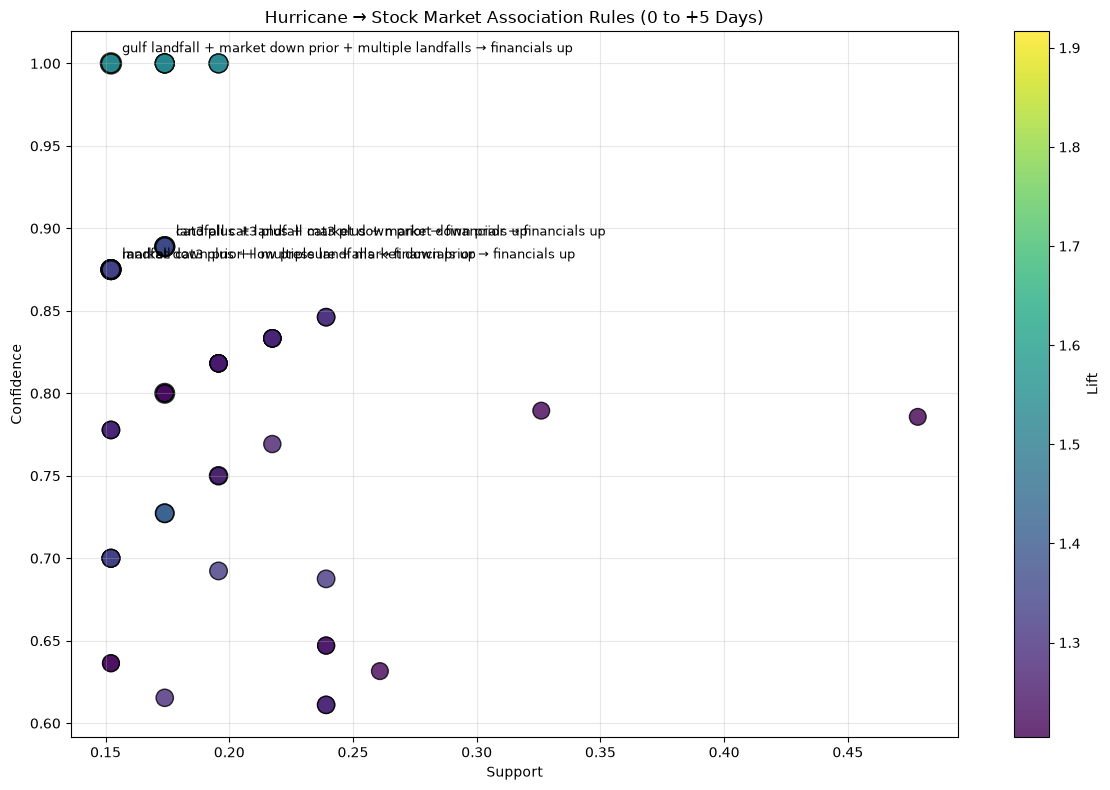

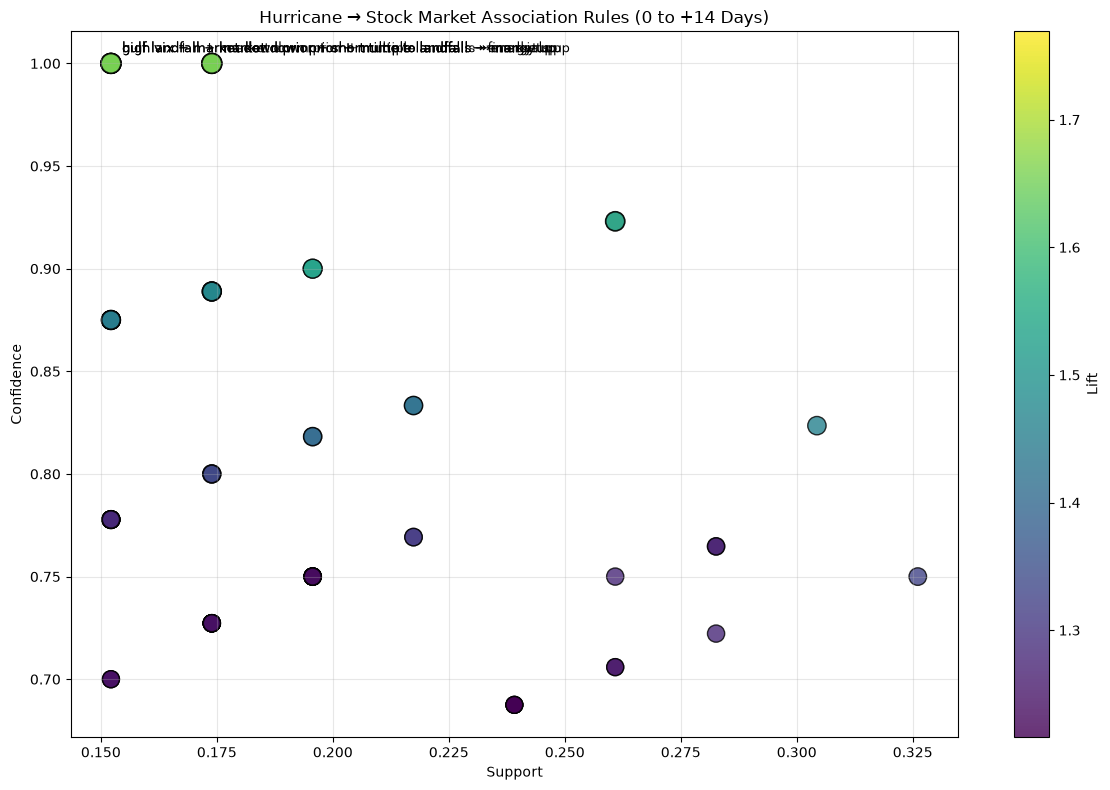

In [24]:
plot_rules(rules_5, "0 to +5 Days")
plot_rules(rules_14, "0 to +14 Days")

In [25]:
def get_rule_key(row):
    return (
        frozenset(row["antecedents"]),
        frozenset(row["consequents"])
    )

keys_5 = {
    get_rule_key(row)
    for _, row in rules_5.iterrows()
}

keys_14 = {
    get_rule_key(row)
    for _, row in rules_14.iterrows()
}

surviving = keys_5 & keys_14

print("Rules surviving both windows:", len(surviving))

for antecedents, consequents in sorted(
    surviving,
    key=lambda x: (
        tuple(sorted(x[0])),
        tuple(sorted(x[1]))
    )
):
    print(
        readable(antecedents),
        "→",
        readable(consequents)
    )

Rules surviving both windows: 36
cat3 plus + gulf landfall + landfall cat3 plus + low pressure + peak season → energy up
cat3 plus + gulf landfall + landfall cat3 plus + peak season → energy up
cat3 plus + gulf landfall + market down prior → market up
cat3 plus + landfall cat3 plus + low pressure + peak season → energy up
cat3 plus + landfall cat3 plus + market down prior → industrials up
cat3 plus + landfall cat3 plus + market down prior → market up
cat3 plus + landfall cat3 plus + peak season → energy up
cat3 plus + multiple landfalls → energy up
cat3 plus + multiple landfalls + peak season → energy up
gulf landfall + high vix + market down prior → financials up
gulf landfall + high vix + short time to landfall → market up
gulf landfall + high vix + short time to landfall → utilities up
gulf landfall + landfall cat3 plus + low pressure + peak season → energy up
gulf landfall + landfall cat3 plus + peak season → energy up
gulf landfall + market down prior → financials up
gulf landfall